In [1]:
import open3d as o3d

FILE_PATH = '/home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-l.stl'

# Load the STL file
mesh = o3d.io.read_triangle_mesh(FILE_PATH)

# Compute normals to ensure the volume is shaded correctly
mesh.compute_vertex_normals()

# Open the 3D viewer
o3d.visualization.draw_geometries([mesh], window_name="3D STL Viewer")


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


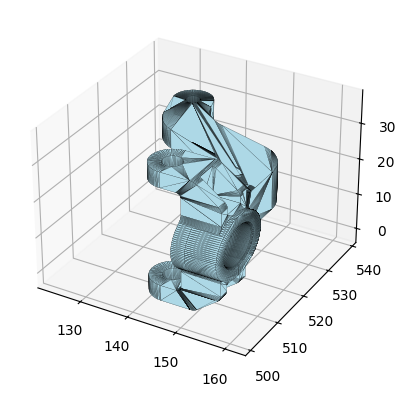

In [2]:
from stl import mesh
from mpl_toolkits import mplot3d
from matplotlib import pyplot as plt
import numpy as np

# Load the STL file
your_mesh = mesh.Mesh.from_file(FILE_PATH)

# Create a new plot
figure = plt.figure()
axes = figure.add_subplot(111, projection='3d')

# Add the vectors to the plot with styling
axes.add_collection3d(mplot3d.art3d.Poly3DCollection(
    your_mesh.vectors, 
    edgecolors='black', 
    facecolors='lightblue', 
    linewidths=0.1
))

# 1. Get exact min and max bounds for X, Y, Z
min_bounds = np.min(your_mesh.vectors.reshape(-1, 3), axis=0)
max_bounds = np.max(your_mesh.vectors.reshape(-1, 3), axis=0)

# 2. Find the midpoint and the largest dimension size
midpoint = (max_bounds + min_bounds) / 2
max_range = np.max(max_bounds - min_bounds)

# 3. Apply uniform limits centered around the model
axes.set_xlim(midpoint[0] - max_range / 2, midpoint[0] + max_range / 2)
axes.set_ylim(midpoint[1] - max_range / 2, midpoint[1] + max_range / 2)
axes.set_zlim(midpoint[2] - max_range / 2, midpoint[2] + max_range / 2)

plt.show()


(256, 256, 256) bool
(260, 260, 260) bool


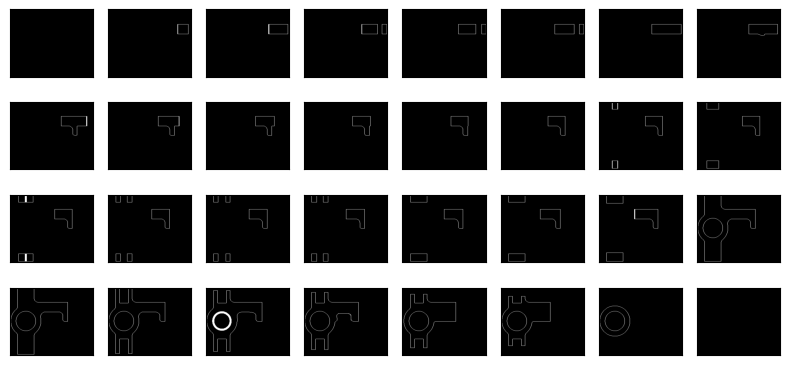

In [3]:
from stl import mesh
from mpl_toolkits import mplot3d
from matplotlib import pyplot as plt
import numpy as np
import open3d as o3d
import open3d.core as o3c
from scipy.ndimage import binary_erosion

# Load the STL file
your_mesh = mesh.Mesh.from_file(FILE_PATH)

# ==============================================================================
# NEW: COMPUTE VOXELS USING OPEN3D RAYCASTING
# ==============================================================================
# 1. Deduplicate vertices for Open3D indexed face format
flattened_vertices = your_mesh.vectors.reshape(-1, 3)
vertices, unique_indices = np.unique(flattened_vertices, axis=0, return_inverse=True)
faces = unique_indices.reshape(-1, 3)

vertices = np.ascontiguousarray(vertices).astype(np.float32)
faces = np.ascontiguousarray(faces).astype(np.int32)

# 2. Setup Open3D Scene
device = o3c.Device("CPU:0")
o3d_mesh = o3d.t.geometry.TriangleMesh(device)
o3d_mesh.vertex.positions = o3c.Tensor(vertices, dtype=o3c.float32, device=device)
o3d_mesh.triangle.indices = o3c.Tensor(faces, dtype=o3c.int32, device=device)

scene = o3d.t.geometry.RaycastingScene()
scene.add_triangles(o3d_mesh)

# 3. Create a structured 3D grid for voxel CORNERS (GRID_RES + 1)
GRID_RES = 256
x_edges = np.linspace(min_bounds[0], max_bounds[0], GRID_RES + 1)
y_edges = np.linspace(min_bounds[1], max_bounds[1], GRID_RES + 1)
z_edges = np.linspace(min_bounds[2], max_bounds[2], GRID_RES + 1)

grid_x, grid_y, grid_z = np.meshgrid(x_edges, y_edges, z_edges, indexing='ij')

# 4. Compute query points at the CENTERS of the voxels
x_centers = (x_edges[:-1] + x_edges[1:]) / 2
y_centers = (y_edges[:-1] + y_edges[1:]) / 2
z_centers = (z_edges[:-1] + z_edges[1:]) / 2

center_x, center_y, center_z = np.meshgrid(x_centers, y_centers, z_centers, indexing='ij')
query_points = np.stack([center_x.ravel(), center_y.ravel(), center_z.ravel()], axis=1)
query_points_tensor = o3c.Tensor(query_points, dtype=o3c.float32, device=device)

# 5. Compute Signed Distance and shape it to the voxel grid (30x30x30)
signed_distances = scene.compute_signed_distance(query_points_tensor).numpy()
voxel_grid = (signed_distances <= 0).reshape(GRID_RES, GRID_RES, GRID_RES)
print(voxel_grid.shape, voxel_grid.dtype)

# 6. Create a hollow shell by subtracting the eroded grid from the solid grid
# 'binary_erosion' shrinks the solid shape inward by 1 voxel layer
eroded_grid = binary_erosion(voxel_grid)

# # Subtracting leaves only the 1-voxel-thick outer crust
voxel_grid = voxel_grid & ~eroded_grid

# ==============================================================================
# PAD THE NUMPY ARRAY AT THE END
# ==============================================================================
PAD_VOXELS = 2  # Add 3 empty voxel layers to all sides

# 1. Pad the binary matrix with zeros (False)
voxel_grid_padded = np.pad(voxel_grid, pad_width=PAD_VOXELS, mode='constant', constant_values=False)

print(voxel_grid_padded.shape, voxel_grid.dtype)

# 2. Compute how much the physical bounds expand due to the padding voxels
voxel_size = (max_bounds - min_bounds) / GRID_RES
physical_pad = PAD_VOXELS * voxel_size

min_bounds_padded = min_bounds - physical_pad
max_bounds_padded = max_bounds + physical_pad

# ==============================================================================
# VISUALIZATION (Updated for the padded array)
# ==============================================================================
num_slices = 32
rows, cols = 4, 8

# Slices are taken along X axis, so each slice shows the Y-Z plane
padded_grid_res = voxel_grid_padded.shape[0]
x_indices = np.linspace(0, padded_grid_res - 1, num_slices, dtype=int)

fig, axes = plt.subplots(rows, cols, figsize=(8, 4))
axes = axes.flatten()

# extent must match the axes shown: Y (horizontal) and Z (vertical)
extent_padded = [min_bounds_padded[1], max_bounds_padded[1], min_bounds_padded[2], max_bounds_padded[2]]

for i, x_idx in enumerate(x_indices):
    ax = axes[i]
    
    # Extract Y-Z slice from the padded array and transpose so Z is vertical
    voxel_slice = voxel_grid_padded[x_idx].astype(float)
    
    ax.imshow(voxel_slice.T, origin='lower', extent=extent_padded, cmap='bone', aspect='equal')
    ax.set_yticks([])
    ax.set_xticks([])

plt.tight_layout()
plt.show()


In [4]:
import pyvista as pv
import numpy as np

data = voxel_grid_padded.astype(np.float32)*1e-2

# Set physical spacing so voxels have correct real-world dimensions
grid = pv.ImageData()
grid.dimensions = np.array(data.shape) + 1
grid.origin = min_bounds_padded
grid.spacing = (max_bounds_padded - min_bounds_padded) / np.array(data.shape)
grid.cell_data["values"] = data.flatten(order="F")

plotter = pv.Plotter()
plotter.add_volume(grid, scalars="values", cmap="bmw", opacity="linear")
plotter.show()


Widget(value='<iframe src="http://localhost:44355/index.html?ui=P_0x78df374bb3e0_0&reconnect=auto" class="pyvi…